# Human–AI Convention Change Model — Full Validation Notebook

This notebook contains:

1. Core Models A–D
2. Model comparison
3. Response curves and posterior-predictive simulation plots
4. Whole-group cross-validation
5. Model D parameter recovery
6. A–D model recovery

Run cells from top to bottom.


In [60]:
# SETTINGS
import sys
from pathlib import Path

DATA_DIR = Path.home() / "Downloads" / "name_game_20 2"
OUT_DIR = DATA_DIR / "python_model_outputs"

STARTS = 12
PPC = 500
SEED = 20260818

# Validation settings
SIMULATION_DRAWS = 500
CV_FOLDS = 6
CV_REPEATS = 1
VALIDATION_STARTS = 3
PARAM_RECOVERY_REPS = 10
MODEL_RECOVERY_REPS = 5

sys.argv = [
    "name_game_abcd_model",
    "--data-dir", str(DATA_DIR),
    "--out-dir", str(OUT_DIR),
    "--starts", str(STARTS),
    "--ppc", str(PPC),
    "--seed", str(SEED),
]

%matplotlib inline

print("Data:", DATA_DIR)
print("Outputs:", OUT_DIR)


Data: /Users/calypsocalcott/Downloads/name_game_20 2
Outputs: /Users/calypsocalcott/Downloads/name_game_20 2/python_model_outputs


## 1. Core model code


In [61]:
#!/usr/bin/env python3
"""
Name Game: Human-AI convention-change models A-D
================================================

Post-change rounds: 8-14
Payoffs: J=10, M=20, N=20

Latent candidate conventions:
    G_J: preserve J
    G_M: transition toward M
    G_N: transition toward N

Prior:
    P(G_J)=1-h
    P(G_M)=P(G_N)=h/2

Switching response:
    p_switch(A) is logistic in inferred advantage A and is parameterized
    by its endpoint probabilities:
        p_lo = P(switch | A=-10)
        p_hi = P(switch | A=20)

Models:
    A: shared h, shared response curve
    B: Human/AI h differ, shared response curve
    C: shared h, Human/AI response curves differ
    D: Human/AI h and response curves differ

Likelihood:
    Actor-marginal likelihood. Each observed action is predicted by
    sum_G q(G) P(action | G), followed by public Bayesian updating.

Lapse:
    epsilon is uniform over 26 letters:
      J/M/N each get epsilon/26
      Other aggregates 23*epsilon/26

Requires:
    numpy pandas scipy matplotlib jax jaxlib

Example:
    python name_game_abcd_model.py \
      --data-dir "$HOME/Downloads/name_game_20 2"
"""

from __future__ import annotations

import argparse
import json
import os
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Sequence, Tuple

os.environ.setdefault("JAX_ENABLE_X64", "true")

import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit, logit
import matplotlib.pyplot as plt

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
from jax.scipy.special import logsumexp


# ---------------------------------------------------------------------
# Fixed experiment quantities
# ---------------------------------------------------------------------

ROUNDS = tuple(range(8, 15))
GROUP_SIZE = 6
PAYOFF_J = 10.0
PAYOFF_MN = 20.0
A_LOW = -10.0
A_HIGH = 20.0
ACTION_NAMES = ("J", "M", "N", "Other")
TYPE_NAMES = ("Human", "AI")
MODELS = ("A", "B", "C", "D")
N_PARAMETERS = {"A": 4, "B": 5, "C": 6, "D": 7}

# Numerical guardrails, not substantive priors.
H_LO, H_HI = 0.005, 0.95
P_LO_MIN, P_LO_MAX = 0.02, 0.97
P_HI_MAX = 0.98
EPS_LO, EPS_HI = 1e-5, 0.20


@dataclass(frozen=True)
class Group:
    key: str
    n_human: int
    n_ai: int
    counts: np.ndarray  # shape: (7 rounds, 2 types, 4 action categories)


# ---------------------------------------------------------------------
# Data loading
# ---------------------------------------------------------------------

def find_input_files(data_dir: Path) -> Tuple[Path, Path]:
    """Find either the local Downloads names or ChatGPT-upload names."""
    candidates = [
        (
            "all_apps_wide-2026-08-05-2.csv",
            "all_apps_wide-2026-08-05-2_part2.csv",
        ),
        (
            "all_apps_wide-2026-08-05-2(1).csv",
            "all_apps_wide-2026-08-05-2_part2(1).csv",
        ),
    ]
    for a, b in candidates:
        p1, p2 = data_dir / a, data_dir / b
        if p1.exists() and p2.exists():
            return p1, p2
    raise FileNotFoundError(
        f"Could not find the two expected CSV files in: {data_dir}"
    )


def action_code(x: object) -> int:
    x = str(x).strip().upper()
    return {"J": 0, "M": 1, "N": 2}.get(x, 3)


def first_parseable_json_list(values: Sequence[object]) -> List[str]:
    """Group-level AI JSON is duplicated across human rows; parse one valid copy."""
    for value in values:
        if pd.isna(value):
            continue
        text = str(value).strip()
        if not text or text == "PENDING":
            continue
        try:
            parsed = json.loads(text)
        except Exception:
            continue
        if isinstance(parsed, list):
            return [str(x) for x in parsed]
    return []


def load_groups(file1: Path, file2: Path) -> Tuple[List[Group], pd.DataFrame, pd.DataFrame]:
    raw = pd.concat(
        [
            pd.read_csv(file1, low_memory=False),
            pd.read_csv(file2, low_memory=False),
        ],
        ignore_index=True,
    ).drop_duplicates()

    # Known excluded/incomplete session from the experiment workflow.
    raw = raw.loc[raw["session.code"] != "un9nmcsy"].copy()

    gid_col = "name_game.8.group.id_in_subsession"
    candidate = raw.loc[raw[gid_col].notna()].copy()

    groups: List[Group] = []
    retained_rows = []
    excluded_rows = []

    for (session, gid), g in candidate.groupby(["session.code", gid_col], sort=False):
        reason = None

        try:
            n_human = int(g["name_game.8.group.num_humans"].dropna().iloc[0])
            n_ai = int(g["name_game.8.group.num_llms"].dropna().iloc[0])
        except Exception:
            reason = "missing composition"
            n_human = n_ai = -1

        if reason is None and n_human + n_ai != GROUP_SIZE:
            reason = "composition does not sum to six"

        # This script is specifically for the mixed-team dataset.
        if reason is None and (n_human <= 0 or n_ai <= 0):
            reason = "not a mixed Human-AI group"

        if reason is None:
            humans = g.loc[g["name_game.8.player.letter_choice"].notna()].copy()
            humans = humans.drop_duplicates("participant.code")
            humans = humans.sort_values("name_game.8.player.id_in_group")
            if len(humans) != n_human:
                reason = f"human count mismatch ({len(humans)} vs {n_human})"

        if reason is None:
            counts = np.zeros((len(ROUNDS), 2, 4), dtype=np.int64)

            for round_index, r in enumerate(ROUNDS):
                human_values = humans[f"name_game.{r}.player.letter_choice"].tolist()
                if len(human_values) != n_human or any(pd.isna(x) for x in human_values):
                    reason = f"incomplete human choices in round {r}"
                    break

                ai_values = first_parseable_json_list(
                    g[f"name_game.{r}.group.llm_choices_json"].tolist()
                )
                if len(ai_values) != n_ai:
                    reason = f"AI count mismatch in round {r} ({len(ai_values)} vs {n_ai})"
                    break

                for x in human_values:
                    counts[round_index, 0, action_code(x)] += 1
                for x in ai_values:
                    counts[round_index, 1, action_code(x)] += 1

            if reason is None:
                if not np.all(counts.sum(axis=(1, 2)) == GROUP_SIZE):
                    reason = "round total != six"
                elif not np.all(counts[:, 0].sum(axis=1) == n_human):
                    reason = "human round totals inconsistent"
                elif not np.all(counts[:, 1].sum(axis=1) == n_ai):
                    reason = "AI round totals inconsistent"

        key = f"{session}_G{int(gid)}"
        if reason is not None:
            excluded_rows.append(
                {
                    "group": key,
                    "session": session,
                    "group_id": int(gid),
                    "reason": reason,
                }
            )
            continue

        groups.append(Group(key, n_human, n_ai, counts))
        retained_rows.append(
            {
                "group": key,
                "session": session,
                "group_id": int(gid),
                "n_human": n_human,
                "n_ai": n_ai,
            }
        )

    if not groups:
        raise RuntimeError("No complete mixed groups were reconstructed.")

    retained = pd.DataFrame(retained_rows)
    excluded = pd.DataFrame(excluded_rows)
    return groups, retained, excluded


# ---------------------------------------------------------------------
# Parameter transforms
# ---------------------------------------------------------------------

def bounded_np(z: float, lo: float, hi: float) -> float:
    return float(lo + (hi - lo) * expit(z))


def inverse_bounded(x: float, lo: float, hi: float) -> float:
    p = np.clip((x - lo) / (hi - lo), 1e-10, 1 - 1e-10)
    return float(logit(p))


def bounded_jax(z, lo: float, hi: float):
    return lo + (hi - lo) * jax.nn.sigmoid(z)


def curve_jax(z_lo, z_delta):
    p_lo = bounded_jax(z_lo, P_LO_MIN, P_LO_MAX)
    fraction = bounded_jax(z_delta, 0.001, 0.999)
    p_hi = p_lo + fraction * (P_HI_MAX - p_lo)
    return p_lo, p_hi


def transform_jax(theta, model: str):
    i = 0

    if model == "A":
        hH = hA = bounded_jax(theta[i], H_LO, H_HI)
        i += 1
        p_loH, p_hiH = curve_jax(theta[i], theta[i + 1])
        i += 2
        p_loA, p_hiA = p_loH, p_hiH

    elif model == "B":
        hH = bounded_jax(theta[i], H_LO, H_HI)
        hA = bounded_jax(theta[i + 1], H_LO, H_HI)
        i += 2
        p_loH, p_hiH = curve_jax(theta[i], theta[i + 1])
        i += 2
        p_loA, p_hiA = p_loH, p_hiH

    elif model == "C":
        hH = hA = bounded_jax(theta[i], H_LO, H_HI)
        i += 1
        p_loH, p_hiH = curve_jax(theta[i], theta[i + 1])
        i += 2
        p_loA, p_hiA = curve_jax(theta[i], theta[i + 1])
        i += 2

    elif model == "D":
        hH = bounded_jax(theta[i], H_LO, H_HI)
        hA = bounded_jax(theta[i + 1], H_LO, H_HI)
        i += 2
        p_loH, p_hiH = curve_jax(theta[i], theta[i + 1])
        i += 2
        p_loA, p_hiA = curve_jax(theta[i], theta[i + 1])
        i += 2

    else:
        raise ValueError(f"Unknown model: {model}")

    epsilon = bounded_jax(theta[i], EPS_LO, EPS_HI)

    return jnp.array(
        [hH, hA, p_loH, p_hiH, p_loA, p_hiA, epsilon],
        dtype=jnp.float64,
    )


def parameters_to_dict(values: np.ndarray) -> Dict[str, float]:
    names = ("hH", "hA", "p_loH", "p_hiH", "p_loA", "p_hiA", "epsilon")
    return {name: float(value) for name, value in zip(names, values)}


def decode_np(theta: np.ndarray, model: str) -> Dict[str, float]:
    return parameters_to_dict(
        np.asarray(transform_jax(jnp.asarray(theta, dtype=jnp.float64), model), dtype=float)
    )


def curve_inverse(p_lo: float, p_hi: float) -> Tuple[float, float]:
    z_lo = inverse_bounded(p_lo, P_LO_MIN, P_LO_MAX)
    fraction = np.clip((p_hi - p_lo) / (P_HI_MAX - p_lo), 0.001, 0.999)
    z_delta = inverse_bounded(fraction, 0.001, 0.999)
    return z_lo, z_delta


def initial_theta(model: str) -> np.ndarray:
    eps = inverse_bounded(0.04, EPS_LO, EPS_HI)

    if model == "A":
        lo, d = curve_inverse(0.70, 0.88)
        return np.array([inverse_bounded(0.35, H_LO, H_HI), lo, d, eps])

    if model == "B":
        lo, d = curve_inverse(0.70, 0.88)
        return np.array(
            [
                inverse_bounded(0.50, H_LO, H_HI),
                inverse_bounded(0.18, H_LO, H_HI),
                lo,
                d,
                eps,
            ]
        )

    if model == "C":
        hlo, hd = curve_inverse(0.84, 0.89)
        alo, ad = curve_inverse(0.55, 0.88)
        return np.array(
            [inverse_bounded(0.35, H_LO, H_HI), hlo, hd, alo, ad, eps]
        )

    if model == "D":
        hlo, hd = curve_inverse(0.84, 0.89)
        alo, ad = curve_inverse(0.55, 0.88)
        return np.array(
            [
                inverse_bounded(0.50, H_LO, H_HI),
                inverse_bounded(0.18, H_LO, H_HI),
                hlo,
                hd,
                alo,
                ad,
                eps,
            ]
        )

    raise ValueError(model)


def encode_parameters(p: Dict[str, float], model: str) -> np.ndarray:
    eps = inverse_bounded(p["epsilon"], EPS_LO, EPS_HI)

    if model == "A":
        h = (p["hH"] + p["hA"]) / 2
        plo = (p["p_loH"] + p["p_loA"]) / 2
        phi = (p["p_hiH"] + p["p_hiA"]) / 2
        lo, d = curve_inverse(plo, phi)
        return np.array([inverse_bounded(h, H_LO, H_HI), lo, d, eps])

    if model == "B":
        plo = (p["p_loH"] + p["p_loA"]) / 2
        phi = (p["p_hiH"] + p["p_hiA"]) / 2
        lo, d = curve_inverse(plo, phi)
        return np.array(
            [
                inverse_bounded(p["hH"], H_LO, H_HI),
                inverse_bounded(p["hA"], H_LO, H_HI),
                lo,
                d,
                eps,
            ]
        )

    if model == "C":
        h = (p["hH"] + p["hA"]) / 2
        hlo, hd = curve_inverse(p["p_loH"], p["p_hiH"])
        alo, ad = curve_inverse(p["p_loA"], p["p_hiA"])
        return np.array(
            [inverse_bounded(h, H_LO, H_HI), hlo, hd, alo, ad, eps]
        )

    if model == "D":
        hlo, hd = curve_inverse(p["p_loH"], p["p_hiH"])
        alo, ad = curve_inverse(p["p_loA"], p["p_hiA"])
        return np.array(
            [
                inverse_bounded(p["hH"], H_LO, H_HI),
                inverse_bounded(p["hA"], H_LO, H_HI),
                hlo,
                hd,
                alo,
                ad,
                eps,
            ]
        )

    raise ValueError(model)


# ---------------------------------------------------------------------
# JAX likelihood
# ---------------------------------------------------------------------

def action_matrix_jax(q, p_lo, p_hi, epsilon):
    advantage_M = PAYOFF_MN * q[1] - PAYOFF_J * q[0]
    advantage_N = PAYOFF_MN * q[2] - PAYOFF_J * q[0]

    logit_lo = jnp.log(p_lo / (1.0 - p_lo))
    logit_hi = jnp.log(p_hi / (1.0 - p_hi))
    beta = (logit_hi - logit_lo) / (A_HIGH - A_LOW)
    alpha = logit_lo - beta * A_LOW

    adopt_M = jax.nn.sigmoid(alpha + beta * advantage_M)
    adopt_N = jax.nn.sigmoid(alpha + beta * advantage_N)

    lapse_one = epsilon / 26.0
    lapse_other = 23.0 * lapse_one
    intentional = 1.0 - epsilon

    return jnp.array(
        [
            [intentional + lapse_one, lapse_one, lapse_one, lapse_other],
            [
                intentional * (1.0 - adopt_M) + lapse_one,
                intentional * adopt_M + lapse_one,
                lapse_one,
                lapse_other,
            ],
            [
                intentional * (1.0 - adopt_N) + lapse_one,
                lapse_one,
                intentional * adopt_N + lapse_one,
                lapse_other,
            ],
        ],
        dtype=jnp.float64,
    )


def group_loglik_jax(counts, parameters):
    hH, hA, p_loH, p_hiH, p_loA, p_hiA, epsilon = parameters

    qH = jnp.array([1.0 - hH, hH / 2.0, hH / 2.0], dtype=jnp.float64)
    qA = jnp.array([1.0 - hA, hA / 2.0, hA / 2.0], dtype=jnp.float64)

    ll = 0.0

    for r in range(len(ROUNDS)):
        human_emissions = action_matrix_jax(qH, p_loH, p_hiH, epsilon)
        ai_emissions = action_matrix_jax(qA, p_loA, p_hiA, epsilon)

        pred_human = qH @ human_emissions
        pred_ai = qA @ ai_emissions

        ll += jnp.sum(counts[r, 0] * jnp.log(jnp.maximum(pred_human, 1e-300)))
        ll += jnp.sum(counts[r, 1] * jnp.log(jnp.maximum(pred_ai, 1e-300)))

        # Public evidence likelihood by candidate policy.
        log_likelihood = jnp.sum(
            counts[r, 0][None, :]
            * jnp.log(jnp.maximum(human_emissions, 1e-300)),
            axis=1,
        )
        log_likelihood += jnp.sum(
            counts[r, 1][None, :]
            * jnp.log(jnp.maximum(ai_emissions, 1e-300)),
            axis=1,
        )

        zH = jnp.log(jnp.maximum(qH, 1e-300)) + log_likelihood
        qH = jnp.exp(zH - logsumexp(zH))

        zA = jnp.log(jnp.maximum(qA, 1e-300)) + log_likelihood
        qA = jnp.exp(zA - logsumexp(zA))

    return ll


def make_objective(model: str):
    def total_nll(theta, counts):
        parameters = transform_jax(theta, model)
        group_ll = jax.vmap(group_loglik_jax, in_axes=(0, None))(counts, parameters)
        return -jnp.sum(group_ll)

    value_and_grad = jax.jit(jax.value_and_grad(total_nll))
    value_only = jax.jit(total_nll)
    return value_and_grad, value_only


# ---------------------------------------------------------------------
# Fitting
# ---------------------------------------------------------------------

def fit_model(
    model: str,
    counts: np.ndarray,
    n_starts: int,
    seed: int,
    warm_starts: List[np.ndarray] | None = None,
):
    value_and_grad, _ = make_objective(model)
    jax_counts = jnp.asarray(counts, dtype=jnp.float64)

    base = initial_theta(model)

    # Compile once before timing optimizer starts.
    compiled_value, _ = value_and_grad(jnp.asarray(base), jax_counts)
    compiled_value.block_until_ready()

    def objective(theta):
        value, gradient = value_and_grad(jnp.asarray(theta), jax_counts)
        return float(value), np.asarray(gradient, dtype=float)

    rng = np.random.default_rng(seed)
    starts = [np.asarray(x, dtype=float) for x in (warm_starts or [])]
    starts.append(base)

    while len(starts) < n_starts:
        starts.append(base + rng.normal(0.0, 0.9, size=base.size))

    best = None
    for start in starts:
        result = minimize(
            objective,
            start,
            jac=True,
            method="L-BFGS-B",
            options={
                "maxiter": 2000,
                "ftol": 1e-12,
                "gtol": 1e-8,
                "maxls": 50,
            },
        )
        if best is None or result.fun < best.fun:
            best = result

    if best is None or not np.isfinite(best.fun):
        raise RuntimeError(f"All optimizer starts failed for Model {model}")

    return best, decode_np(best.x, model)


# ---------------------------------------------------------------------
# Independent NumPy likelihood used for self-test and simulation
# ---------------------------------------------------------------------

def switch_probability_np(advantage: float, p_lo: float, p_hi: float) -> float:
    beta = (logit(p_hi) - logit(p_lo)) / (A_HIGH - A_LOW)
    alpha = logit(p_lo) - beta * A_LOW
    return float(expit(alpha + beta * advantage))


def action_matrix_np(q: np.ndarray, p_lo: float, p_hi: float, epsilon: float) -> np.ndarray:
    q = np.asarray(q, dtype=float)
    advantage_M = PAYOFF_MN * q[1] - PAYOFF_J * q[0]
    advantage_N = PAYOFF_MN * q[2] - PAYOFF_J * q[0]
    adopt_M = switch_probability_np(advantage_M, p_lo, p_hi)
    adopt_N = switch_probability_np(advantage_N, p_lo, p_hi)

    lapse_one = epsilon / 26.0
    lapse_other = 23.0 * lapse_one
    intentional = 1.0 - epsilon

    matrix = np.array(
        [
            [intentional + lapse_one, lapse_one, lapse_one, lapse_other],
            [intentional * (1-adopt_M) + lapse_one, intentional*adopt_M + lapse_one, lapse_one, lapse_other],
            [intentional * (1-adopt_N) + lapse_one, lapse_one, intentional*adopt_N + lapse_one, lapse_other],
        ],
        dtype=float,
    )

    if not np.isfinite(matrix).all():
        raise ValueError("Non-finite action probability")
    if np.any(matrix <= 0):
        raise ValueError("Action probabilities must be positive")
    if not np.allclose(matrix.sum(axis=1), 1.0, atol=1e-10):
        raise ValueError("Action probabilities do not sum to one")
    return matrix


def update_beliefs_np(qH, qA, round_counts, p):
    human_emissions = action_matrix_np(qH, p["p_loH"], p["p_hiH"], p["epsilon"])
    ai_emissions = action_matrix_np(qA, p["p_loA"], p["p_hiA"], p["epsilon"])

    log_likelihood = (
        round_counts[0][None, :] * np.log(human_emissions)
    ).sum(axis=1)
    log_likelihood += (
        round_counts[1][None, :] * np.log(ai_emissions)
    ).sum(axis=1)

    def update(q):
        z = np.log(np.maximum(q, 1e-300)) + log_likelihood
        z -= np.max(z)
        out = np.exp(z)
        return out / out.sum()

    return update(qH), update(qA)


def group_loglik_np(group: Group, p: Dict[str, float]) -> float:
    qH = np.array([1-p["hH"], p["hH"]/2, p["hH"]/2], dtype=float)
    qA = np.array([1-p["hA"], p["hA"]/2, p["hA"]/2], dtype=float)
    ll = 0.0

    for r in range(len(ROUNDS)):
        H = action_matrix_np(qH, p["p_loH"], p["p_hiH"], p["epsilon"])
        A = action_matrix_np(qA, p["p_loA"], p["p_hiA"], p["epsilon"])
        predH = qH @ H
        predA = qA @ A
        ll += float(group.counts[r, 0] @ np.log(predH))
        ll += float(group.counts[r, 1] @ np.log(predA))
        qH, qA = update_beliefs_np(qH, qA, group.counts[r], p)

    return ll


def self_tests(groups: List[Group], counts: np.ndarray):
    assert PAYOFF_J == 10.0
    assert PAYOFF_MN == 20.0
    assert counts.shape == (len(groups), 7, 2, 4)
    assert np.all(counts.sum(axis=(2, 3)) == GROUP_SIZE)

    for model in MODELS:
        theta = initial_theta(model)
        p = decode_np(theta, model)
        assert p["p_hiH"] >= p["p_loH"]
        assert p["p_hiA"] >= p["p_loA"]

        q = np.array([1-p["hH"], p["hH"]/2, p["hH"]/2])
        matrix = action_matrix_np(q, p["p_loH"], p["p_hiH"], p["epsilon"])
        assert np.allclose(matrix.sum(axis=1), 1.0)
        assert np.isfinite(group_loglik_np(groups[0], p))

        _, value_only = make_objective(model)
        jax_nll = float(value_only(jnp.asarray(theta), jnp.asarray(counts)))
        numpy_nll = -sum(group_loglik_np(g, p) for g in groups)
        if not np.isclose(jax_nll, numpy_nll, atol=1e-8, rtol=1e-10):
            raise AssertionError(
                f"JAX/NumPy likelihood mismatch for Model {model}: "
                f"{jax_nll} vs {numpy_nll}"
            )


# ---------------------------------------------------------------------
# Predictive simulation
# ---------------------------------------------------------------------

def simulate_group(group: Group, p: Dict[str, float], rng: np.random.Generator) -> np.ndarray:
    qH = np.array([1-p["hH"], p["hH"]/2, p["hH"]/2], dtype=float)
    qA = np.array([1-p["hA"], p["hA"]/2, p["hA"]/2], dtype=float)
    counts = np.zeros((7, 2, 4), dtype=np.int64)

    for r in range(7):
        H = action_matrix_np(qH, p["p_loH"], p["p_hiH"], p["epsilon"])
        A = action_matrix_np(qA, p["p_loA"], p["p_hiA"], p["epsilon"])
        predH = qH @ H
        predA = qA @ A

        counts[r, 0] = rng.multinomial(group.n_human, predH)
        counts[r, 1] = rng.multinomial(group.n_ai, predA)
        qH, qA = update_beliefs_np(qH, qA, counts[r], p)

    return counts


def switching_ppc(groups: List[Group], p: Dict[str, float], n_sim: int, seed: int) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    rows = []

    for simulation in range(n_sim):
        numerator = np.zeros((7, 2), dtype=float)
        denominator = np.zeros((7, 2), dtype=float)

        for group in groups:
            sim = simulate_group(group, p, rng)
            numerator += sim[:, :, 1] + sim[:, :, 2]
            denominator += sim.sum(axis=2)

        rates = numerator / denominator
        for r_index, r in enumerate(ROUNDS):
            for type_index, type_name in enumerate(TYPE_NAMES):
                rows.append(
                    {
                        "simulation": simulation,
                        "round": r,
                        "type": type_name,
                        "switch_rate": rates[r_index, type_index],
                    }
                )

    raw = pd.DataFrame(rows)
    return (
        raw.groupby(["round", "type"], as_index=False)
        .agg(
            simulated_mean=("switch_rate", "mean"),
            lower_95=("switch_rate", lambda x: np.quantile(x, 0.025)),
            upper_95=("switch_rate", lambda x: np.quantile(x, 0.975)),
        )
    )


def observed_switching(groups: List[Group]) -> pd.DataFrame:
    rows = []
    for r_index, r in enumerate(ROUNDS):
        for type_index, type_name in enumerate(TYPE_NAMES):
            numerator = sum(
                g.counts[r_index, type_index, 1] + g.counts[r_index, type_index, 2]
                for g in groups
            )
            denominator = sum(g.counts[r_index, type_index].sum() for g in groups)
            rows.append(
                {
                    "round": r,
                    "type": type_name,
                    "switch_rate": numerator / denominator,
                    "n": int(denominator),
                }
            )
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------
# Diagnostics / plotting
# ---------------------------------------------------------------------

def boundary_flags(p: Dict[str, float]) -> List[str]:
    flags = []
    if p["hH"] < H_LO + 0.01 or p["hH"] > H_HI - 0.01:
        flags.append("hH near bound")
    if p["hA"] < H_LO + 0.01 or p["hA"] > H_HI - 0.01:
        flags.append("hA near bound")
    if p["p_loH"] < P_LO_MIN + 0.01 or p["p_loH"] > P_LO_MAX - 0.01:
        flags.append("p_loH near bound")
    if p["p_loA"] < P_LO_MIN + 0.01 or p["p_loA"] > P_LO_MAX - 0.01:
        flags.append("p_loA near bound")
    if p["p_hiH"] > P_HI_MAX - 0.01:
        flags.append("p_hiH near upper bound")
    if p["p_hiA"] > P_HI_MAX - 0.01:
        flags.append("p_hiA near upper bound")
    return flags


def plot_switching(observed: pd.DataFrame, ppc: pd.DataFrame, output: Path):
    fig, ax = plt.subplots(figsize=(7.5, 4.8))

    for type_name in TYPE_NAMES:
        sim = ppc.loc[ppc["type"] == type_name]
        obs = observed.loc[observed["type"] == type_name]
        line = ax.plot(
            sim["round"],
            sim["simulated_mean"],
            marker="o",
            label=f"{type_name} simulated",
        )[0]
        ax.fill_between(
            sim["round"],
            sim["lower_95"],
            sim["upper_95"],
            alpha=0.15,
            color=line.get_color(),
        )
        ax.plot(
            obs["round"],
            obs["switch_rate"],
            marker="x",
            linestyle="--",
            color=line.get_color(),
            label=f"{type_name} observed",
        )

    ax.set_ylim(0, 1)
    ax.set_xticks(ROUNDS)
    ax.set_xlabel("Round")
    ax.set_ylabel("Proportion choosing M or N")
    ax.set_title("Model D predictive check")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(output, dpi=180)
    plt.show()


def plot_response_curves(p: Dict[str, float], output: Path):
    advantages = np.linspace(A_LOW, A_HIGH, 300)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for label, lo_key, hi_key in (
        ("Human", "p_loH", "p_hiH"),
        ("AI", "p_loA", "p_hiA"),
    ):
        probs = [
            switch_probability_np(a, p[lo_key], p[hi_key])
            for a in advantages
        ]
        ax.plot(advantages, probs, label=label)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Inferred transition advantage")
    ax.set_ylabel("Switch probability")
    ax.set_title("Model D response curves")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(output, dpi=180)
    plt.show()


# ---------------------------------------------------------------------
# Main
# ---------------------------------------------------------------------

def main():
    parser = argparse.ArgumentParser()
    parser.add_argument(
        "--data-dir",
        type=Path,
        default=Path.home() / "Downloads" / "name_game_20 2",
    )
    parser.add_argument("--out-dir", type=Path, default=None)
    parser.add_argument("--starts", type=int, default=12)
    parser.add_argument("--ppc", type=int, default=500)
    parser.add_argument("--seed", type=int, default=20260818)
    args = parser.parse_args()

    if args.starts < 3:
        raise ValueError("Use at least 3 optimization starts for the main analysis.")
    if args.ppc < 0:
        raise ValueError("--ppc must be >= 0")

    file1, file2 = find_input_files(args.data_dir)
    output_dir = args.out_dir or (args.data_dir / "python_model_outputs")
    output_dir.mkdir(parents=True, exist_ok=True)

    start_time = time.perf_counter()

    groups, retained, excluded = load_groups(file1, file2)
    counts = np.stack([g.counts for g in groups]).astype(np.float64)
    n_observations = len(groups) * GROUP_SIZE * len(ROUNDS)

    print(f"Loaded {len(groups)} complete mixed groups; {n_observations} choices.")
    print(retained.groupby(["n_human", "n_ai"]).size().rename("groups").to_string())

    # Current two pilot exports should reconstruct exactly this dataset.
    if len(groups) != 18 or n_observations != 756:
        print(
            "WARNING: current reference exports previously reconstructed as "
            "18 groups / 756 choices. Inspect retained_groups.csv and exclusions.csv."
        )

    retained.to_csv(output_dir / "retained_groups.csv", index=False)
    excluded.to_csv(output_dir / "exclusions.csv", index=False)

    self_tests(groups, counts)
    print("Self-tests passed, including independent NumPy/JAX likelihood agreement.")

    fits = {}
    comparison_rows = []

    for model in MODELS:
        warm = []
        if model == "B" and "A" in fits:
            warm.append(encode_parameters(fits["A"][1], "B"))
        elif model == "C" and "A" in fits:
            warm.append(encode_parameters(fits["A"][1], "C"))
        elif model == "D":
            warm.append(encode_parameters(fits["B"][1], "D"))
            warm.append(encode_parameters(fits["C"][1], "D"))

        t_model = time.perf_counter()
        result, parameters = fit_model(
            model,
            counts,
            n_starts=args.starts,
            seed=args.seed + ord(model),
            warm_starts=warm,
        )
        fits[model] = (result, parameters)

        k = N_PARAMETERS[model]
        aic = 2 * result.fun + 2 * k
        bic = 2 * result.fun + k * np.log(n_observations)
        flags = boundary_flags(parameters)

        comparison_rows.append(
            {
                "model": model,
                "NLL": result.fun,
                "k": k,
                "AIC": aic,
                "BIC": bic,
                "optimizer_success": bool(result.success),
                "optimizer_message": str(result.message),
                "boundary_flags": "; ".join(flags),
                **parameters,
            }
        )

        print(
            f"Model {model}: NLL={result.fun:.3f}, AIC={aic:.3f}, "
            f"BIC={bic:.3f}, time={time.perf_counter()-t_model:.2f}s"
        )
        if flags:
            print("  Boundary diagnostic:", ", ".join(flags))

    comparison = pd.DataFrame(comparison_rows)
    comparison["delta_AIC"] = comparison["AIC"] - comparison["AIC"].min()
    comparison["delta_BIC"] = comparison["BIC"] - comparison["BIC"].min()

    # Nested-model sanity checks.
    nlls = comparison.set_index("model")["NLL"]
    if nlls["B"] > nlls["A"] + 1e-5:
        raise RuntimeError("Model B fit is worse than nested Model A; increase --starts.")
    if nlls["C"] > nlls["A"] + 1e-5:
        raise RuntimeError("Model C fit is worse than nested Model A; increase --starts.")
    if nlls["D"] > min(nlls["B"], nlls["C"]) + 1e-5:
        raise RuntimeError("Model D fit is worse than a nested model; increase --starts.")

    print("\nMODEL COMPARISON")
    print(
        comparison[
            [
                "model", "NLL", "AIC", "BIC", "delta_AIC", "delta_BIC",
                "hH", "hA", "p_loH", "p_hiH", "p_loA", "p_hiA", "epsilon",
                "boundary_flags",
            ]
        ].to_string(index=False)
    )

    comparison.to_csv(output_dir / "model_comparison_and_parameters.csv", index=False)

    observed = observed_switching(groups)
    observed.to_csv(output_dir / "observed_switching.csv", index=False)

    # Model D response curve output.
    pD = fits["D"][1]
    response_rows = []
    for advantage in np.linspace(A_LOW, A_HIGH, 301):
        response_rows.append(
            {
                "advantage": advantage,
                "Human": switch_probability_np(advantage, pD["p_loH"], pD["p_hiH"]),
                "AI": switch_probability_np(advantage, pD["p_loA"], pD["p_hiA"]),
            }
        )
    pd.DataFrame(response_rows).to_csv(output_dir / "model_D_response_curves.csv", index=False)
    plot_response_curves(pD, output_dir / "model_D_response_curves.png")

    if args.ppc > 0:
        t_ppc = time.perf_counter()
        ppc = switching_ppc(groups, pD, args.ppc, args.seed + 999)
        ppc.to_csv(output_dir / "model_D_switching_ppc.csv", index=False)
        plot_switching(observed, ppc, output_dir / "model_D_switching_ppc.png")
        print(
            f"Model D PPC ({args.ppc} simulated datasets): "
            f"{time.perf_counter()-t_ppc:.2f}s"
        )

    print(f"\nFinished in {time.perf_counter()-start_time:.2f}s")
    print(f"Outputs: {output_dir}")

    return {
        "groups": groups,
        "counts": counts,
        "retained": retained,
        "excluded": excluded,
        "fits": fits,
        "comparison": comparison,
        "observed": observed,
        "output_dir": output_dir,
        "args": args,
    }


## 2. Fit Models A–D


Loaded 18 complete mixed groups; 756 choices.
n_human  n_ai
2        4       5
3        3       6
4        2       7
Self-tests passed, including independent NumPy/JAX likelihood agreement.
Model A: NLL=400.883, AIC=809.767, BIC=828.279, time=1.40s
  Boundary diagnostic: p_hiH near upper bound, p_hiA near upper bound
Model B: NLL=379.227, AIC=768.453, BIC=791.593, time=1.49s
  Boundary diagnostic: hA near bound, p_hiH near upper bound, p_hiA near upper bound
Model C: NLL=399.830, AIC=811.660, BIC=839.428, time=1.35s
  Boundary diagnostic: p_hiH near upper bound, p_hiA near upper bound
Model D: NLL=361.885, AIC=737.771, BIC=770.167, time=1.56s
  Boundary diagnostic: hA near bound, p_hiA near upper bound

MODEL COMPARISON
model        NLL        AIC        BIC  delta_AIC  delta_BIC       hH       hA    p_loH    p_hiH    p_loA    p_hiA  epsilon                                                boundary_flags
    A 400.883334 809.766669 828.278834  71.996156  58.112032 0.341895 0.341895 0.697

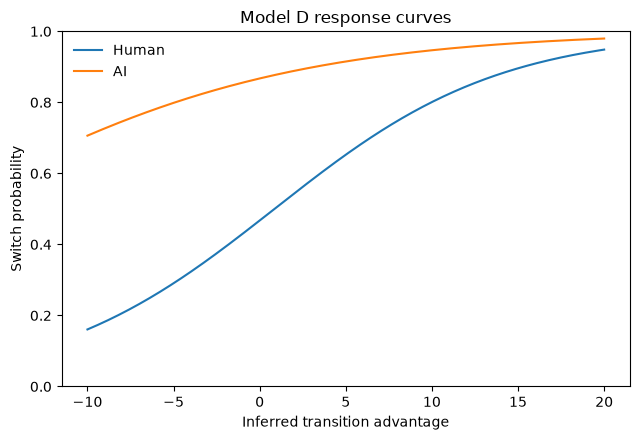

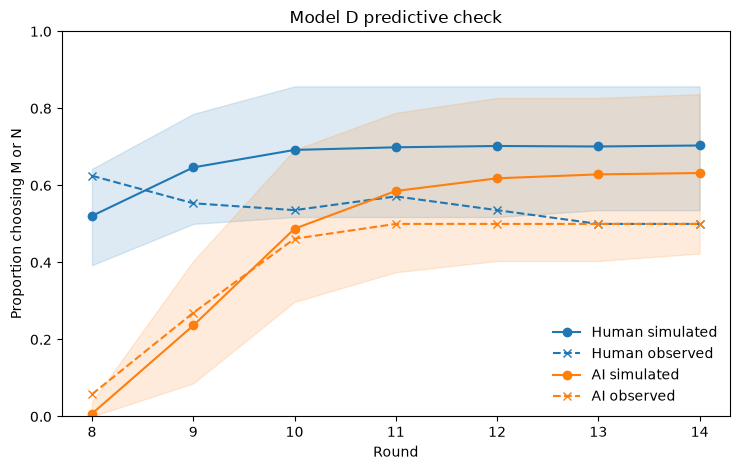

Model D PPC (500 simulated datasets): 5.25s

Finished in 12.87s
Outputs: /Users/calypsocalcott/Downloads/name_game_20 2/python_model_outputs


,model,NLL,k,AIC,BIC,optimizer_success,optimizer_message,boundary_flags,hH,hA,p_loH,p_hiH,p_loA,p_hiA,epsilon,delta_AIC,delta_BIC
0,A,400.883334,4,809.766669,828.278834,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,p_hiH near upper bound; p_hiA near upper bound,0.341895,0.341895,0.697710,0.979718,0.697710,0.979718,0.080496,71.996156,58.112032
1,B,379.226601,5,768.453202,791.593409,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,hA near bound; p_hiH near upper bound; p_hiA n...,0.625195,0.005000,0.648413,0.978496,0.648413,0.978496,0.052167,30.682689,21.426607
2,C,399.829774,6,811.659548,839.427796,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,p_hiH near upper bound; p_hiA near upper bound,0.339368,0.339368,0.656068,0.979676,0.735461,0.979755,0.076943,73.889036,69.260994
3,D,361.885256,7,737.770512,770.166802,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,hA near bound; p_hiA near upper bound,0.800254,0.005000,0.160668,0.948557,0.706310,0.979726,0.058949,0.000000,0.000000


In [62]:
RUN = main()

groups = RUN["groups"]
counts = RUN["counts"]
fits = RUN["fits"]
comparison = RUN["comparison"]
observed = RUN["observed"]
output_dir = RUN["output_dir"]

display(comparison)


## 3. Simulation plot

Observed M/N adoption is plotted against Model D simulations. The shaded area is the central 95% simulation interval.


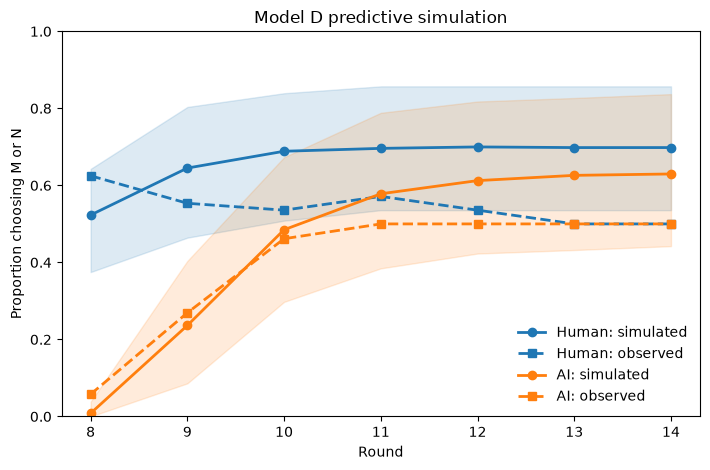

In [63]:
pD = fits["D"][1]

simulation_ppc = switching_ppc(
    groups,
    pD,
    n_sim=SIMULATION_DRAWS,
    seed=SEED + 9999,
)

fig, ax = plt.subplots(figsize=(7.2, 4.8))

for type_name in TYPE_NAMES:
    sim = simulation_ppc.loc[
        simulation_ppc["type"] == type_name
    ].sort_values("round")

    obs = observed.loc[
        observed["type"] == type_name
    ].sort_values("round")

    line = ax.plot(
        sim["round"],
        sim["simulated_mean"],
        marker="o",
        linewidth=2,
        label=f"{type_name}: simulated",
    )[0]

    ax.fill_between(
        sim["round"].to_numpy(),
        sim["lower_95"].to_numpy(),
        sim["upper_95"].to_numpy(),
        alpha=0.15,
        color=line.get_color(),
    )

    ax.plot(
        obs["round"],
        obs["switch_rate"],
        marker="s",
        linestyle="--",
        linewidth=2,
        color=line.get_color(),
        label=f"{type_name}: observed",
    )

ax.set(
    xlabel="Round",
    ylabel="Proportion choosing M or N",
    ylim=(0, 1),
    xticks=ROUNDS,
    title="Model D predictive simulation",
)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

simulation_ppc.to_csv(
    output_dir / "model_D_simulation_plot_data.csv",
    index=False,
)


## 4. Whole-group cross-validation

Entire six-player groups are held out. All models are fit on the remaining groups, and predictive log likelihood is evaluated on unseen groups.


,model,total_test_NLL,mean_test_NLL_per_choice,sd_test_NLL_per_choice,delta_test_NLL
0,D,398.234947,0.526766,0.253679,0.000000
1,B,454.628634,0.601361,0.355403,56.393687
2,A,500.546671,0.662099,0.358974,102.311723
3,C,512.700521,0.678175,0.383647,114.465573


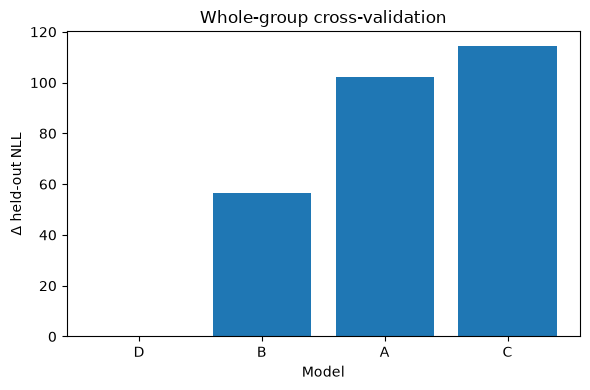

In [64]:
_validation_cache = {}

def fit_model_validation(model, counts_use, n_starts, seed, warm_starts=None):
    key = (model, counts_use.shape[0])

    if key not in _validation_cache:
        _validation_cache[key] = make_objective(model)

    value_and_grad, _ = _validation_cache[key]
    jax_counts = jnp.asarray(counts_use, dtype=jnp.float64)
    base = initial_theta(model)

    # Compile.
    v, g = value_and_grad(jnp.asarray(base), jax_counts)
    v.block_until_ready()

    def obj(theta):
        value, grad = value_and_grad(
            jnp.asarray(theta, dtype=jnp.float64),
            jax_counts,
        )
        return float(value), np.asarray(grad, dtype=float)

    rng = np.random.default_rng(seed)
    starts = [np.asarray(x, dtype=float) for x in (warm_starts or [])]
    starts.append(base)

    while len(starts) < n_starts:
        starts.append(base + rng.normal(0, 0.9, size=base.size))

    best = None
    for start in starts:
        result = minimize(
            obj,
            start,
            jac=True,
            method="L-BFGS-B",
            options={
                "maxiter": 2000,
                "ftol": 1e-12,
                "gtol": 1e-8,
                "maxls": 50,
            },
        )
        if np.isfinite(result.fun) and (
            best is None or result.fun < best.fun
        ):
            best = result

    if best is None:
        raise RuntimeError(f"All validation fits failed for Model {model}")

    return best, decode_np(best.x, model)


def fit_all_validation_models(counts_use, n_starts, seed):
    out = {}

    for model in MODELS:
        warm = []

        if model == "B":
            warm = [encode_parameters(out["A"][1], "B")]
        elif model == "C":
            warm = [encode_parameters(out["A"][1], "C")]
        elif model == "D":
            warm = [
                encode_parameters(out["B"][1], "D"),
                encode_parameters(out["C"][1], "D"),
            ]

        out[model] = fit_model_validation(
            model,
            counts_use,
            n_starts,
            seed + ord(model),
            warm,
        )

    return out


def run_group_cv(groups, k=6, repeats=1, n_starts=3, seed=20260818):
    rng = np.random.default_rng(seed)
    all_counts = np.stack([g.counts for g in groups]).astype(float)
    rows = []

    for repeat in range(repeats):
        perm = rng.permutation(len(groups))
        folds = np.array_split(perm, k)

        for fold_number, test_idx in enumerate(folds, start=1):
            train_idx = np.setdiff1d(
                np.arange(len(groups)),
                test_idx,
            )

            train_counts = all_counts[train_idx]

            fold_fits = fit_all_validation_models(
                train_counts,
                n_starts=n_starts,
                seed=seed + repeat * 10000 + fold_number * 100,
            )

            for model in MODELS:
                result, pars = fold_fits[model]

                test_ll = sum(
                    group_loglik_np(groups[i], pars)
                    for i in test_idx
                )

                n_test = len(test_idx) * GROUP_SIZE * len(ROUNDS)

                rows.append({
                    "repeat": repeat + 1,
                    "fold": fold_number,
                    "model": model,
                    "test_NLL": -test_ll,
                    "test_NLL_per_choice": -test_ll / n_test,
                })

    raw = pd.DataFrame(rows)

    summary = (
        raw.groupby("model", as_index=False)
        .agg(
            total_test_NLL=("test_NLL", "sum"),
            mean_test_NLL_per_choice=("test_NLL_per_choice", "mean"),
            sd_test_NLL_per_choice=("test_NLL_per_choice", "std"),
        )
        .sort_values("total_test_NLL")
        .reset_index(drop=True)
    )

    summary["delta_test_NLL"] = (
        summary["total_test_NLL"] -
        summary["total_test_NLL"].min()
    )

    return raw, summary


cv_raw, cv_summary = run_group_cv(
    groups,
    k=CV_FOLDS,
    repeats=CV_REPEATS,
    n_starts=VALIDATION_STARTS,
    seed=SEED + 20000,
)

display(cv_summary)

fig, ax = plt.subplots(figsize=(6.0, 4.0))
plot_dat = cv_summary.sort_values("delta_test_NLL")
ax.bar(plot_dat["model"], plot_dat["delta_test_NLL"])
ax.set(
    xlabel="Model",
    ylabel="Δ held-out NLL",
    title="Whole-group cross-validation",
)
fig.tight_layout()
plt.show()

cv_raw.to_csv(output_dir / "group_cv_raw.csv", index=False)
cv_summary.to_csv(output_dir / "group_cv_summary.csv", index=False)


## 5. Model D parameter recovery

Synthetic datasets are generated from varied Model D parameter values. Model D is then refit without using the generating values as initialization.


/var/folders/nt/p87wm42s515gkrcr7c91c93r0000gn/T/ipykernel_18829/615360285.py:68: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,parameter,correlation,bias,MAE,RMSE
0,epsilon,0.976672,-0.002969,0.005228,0.006172
1,hA,0.755531,0.066303,0.090937,0.139655
2,hH,0.685123,0.002495,0.072278,0.086917
3,p_hiA,0.965438,0.000654,0.016694,0.020088
4,p_hiH,0.956046,0.000088,0.015358,0.018569
5,p_loA,0.736756,-0.061279,0.110558,0.158140
6,p_loH,0.979206,0.036731,0.036731,0.044587


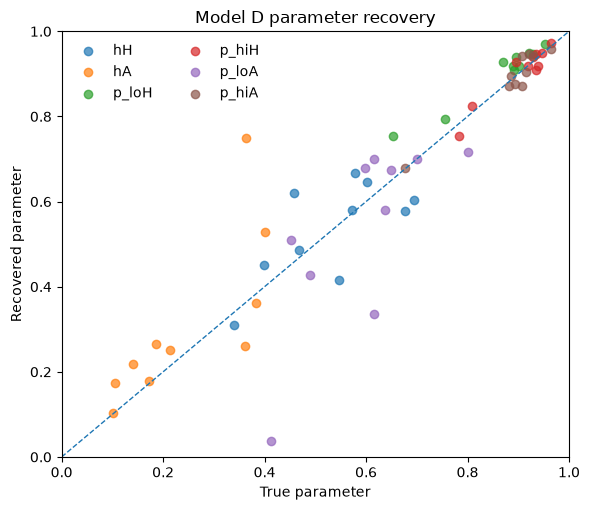

In [65]:
PARAMETER_NAMES = (
    "hH", "hA",
    "p_loH", "p_hiH",
    "p_loA", "p_hiA",
    "epsilon",
)

def simulate_dataset(template_groups, pars, rng):
    return [
        Group(
            key=g.key,
            n_human=g.n_human,
            n_ai=g.n_ai,
            counts=simulate_group(g, pars, rng),
        )
        for g in template_groups
    ]


def run_parameter_recovery(
    groups,
    n_reps=10,
    n_starts=3,
    seed=20260818,
):
    rng = np.random.default_rng(seed)
    base = initial_theta("D")
    rows = []

    for rep in range(1, n_reps + 1):
        true_theta = base + rng.normal(
            0,
            0.8,
            size=base.size,
        )
        true_pars = decode_np(true_theta, "D")

        sim_groups = simulate_dataset(
            groups,
            true_pars,
            rng,
        )
        sim_counts = np.stack(
            [g.counts for g in sim_groups]
        ).astype(float)

        result, recovered = fit_model_validation(
            "D",
            sim_counts,
            n_starts=n_starts,
            seed=seed + rep * 100,
            warm_starts=None,
        )

        for par in PARAMETER_NAMES:
            rows.append({
                "rep": rep,
                "parameter": par,
                "true": true_pars[par],
                "recovered": recovered[par],
                "error": recovered[par] - true_pars[par],
            })

    raw = pd.DataFrame(rows)

    summary = (
        raw.groupby("parameter")
        .apply(
            lambda d: pd.Series({
                "correlation": d["true"].corr(d["recovered"]),
                "bias": d["error"].mean(),
                "MAE": d["error"].abs().mean(),
                "RMSE": np.sqrt(np.mean(d["error"] ** 2)),
            })
        )
        .reset_index()
    )

    return raw, summary


parameter_recovery, parameter_recovery_summary = run_parameter_recovery(
    groups,
    n_reps=PARAM_RECOVERY_REPS,
    n_starts=VALIDATION_STARTS,
    seed=SEED + 30000,
)

display(parameter_recovery_summary)

fig, ax = plt.subplots(figsize=(6.0, 5.2))
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)

for par in [x for x in PARAMETER_NAMES if x != "epsilon"]:
    d = parameter_recovery.loc[
        parameter_recovery["parameter"] == par
    ]
    ax.scatter(
        d["true"],
        d["recovered"],
        alpha=0.7,
        label=par,
    )

ax.set(
    xlabel="True parameter",
    ylabel="Recovered parameter",
    xlim=(0, 1),
    ylim=(0, 1),
    title="Model D parameter recovery",
)
ax.legend(frameon=False, ncol=2)
fig.tight_layout()
plt.show()

parameter_recovery.to_csv(
    output_dir / "parameter_recovery_raw.csv",
    index=False,
)
parameter_recovery_summary.to_csv(
    output_dir / "parameter_recovery_summary.csv",
    index=False,
)


## 6. A–D model recovery

Each fitted model generates synthetic datasets. All four models are fit to every synthetic dataset. AIC and BIC confusion matrices show whether the design can distinguish the candidate mechanisms.


AIC recovery


winner_AIC,A,B,C,D
generating_model,,,,
A,1.0,0.0,0.0,0.0
B,0.0,1.0,0.0,0.0
C,0.8,0.0,0.2,0.0
D,0.0,0.0,0.0,1.0


BIC recovery


winner_BIC,A,B,C,D
generating_model,,,,
A,1.0,0.0,0,0.0
B,0.0,1.0,0,0.0
C,1.0,0.0,0,0.0
D,0.0,0.0,0,1.0


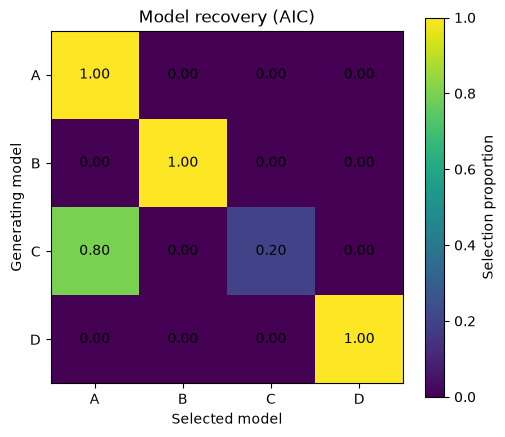

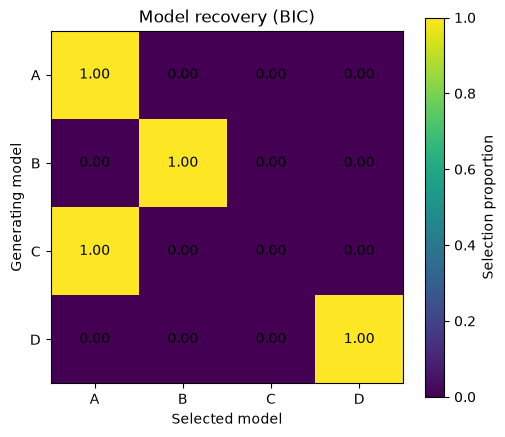

In [66]:
def run_model_recovery(
    groups,
    empirical_fits,
    n_reps=5,
    n_starts=3,
    seed=20260818,
):
    rng = np.random.default_rng(seed)
    n_obs = len(groups) * GROUP_SIZE * len(ROUNDS)
    rows = []

    for generating_model in MODELS:
        generating_pars = empirical_fits[generating_model][1]

        for rep in range(1, n_reps + 1):
            sim_groups = simulate_dataset(
                groups,
                generating_pars,
                rng,
            )
            sim_counts = np.stack(
                [g.counts for g in sim_groups]
            ).astype(float)

            candidate_fits = fit_all_validation_models(
                sim_counts,
                n_starts=n_starts,
                seed=seed + 10000 * MODELS.index(generating_model) + rep * 100,
            )

            metrics = []
            for candidate in MODELS:
                result, _ = candidate_fits[candidate]
                k = N_PARAMETERS[candidate]

                metrics.append({
                    "candidate": candidate,
                    "AIC": 2 * result.fun + 2 * k,
                    "BIC": 2 * result.fun + k * np.log(n_obs),
                })

            winner_aic = min(metrics, key=lambda x: x["AIC"])["candidate"]
            winner_bic = min(metrics, key=lambda x: x["BIC"])["candidate"]

            rows.append({
                "generating_model": generating_model,
                "rep": rep,
                "winner_AIC": winner_aic,
                "winner_BIC": winner_bic,
            })

    raw = pd.DataFrame(rows)

    aic_matrix = pd.crosstab(
        raw["generating_model"],
        raw["winner_AIC"],
        normalize="index",
    ).reindex(index=MODELS, columns=MODELS, fill_value=0)

    bic_matrix = pd.crosstab(
        raw["generating_model"],
        raw["winner_BIC"],
        normalize="index",
    ).reindex(index=MODELS, columns=MODELS, fill_value=0)

    return raw, aic_matrix, bic_matrix


model_recovery, recovery_AIC, recovery_BIC = run_model_recovery(
    groups,
    fits,
    n_reps=MODEL_RECOVERY_REPS,
    n_starts=VALIDATION_STARTS,
    seed=SEED + 40000,
)

print("AIC recovery")
display(recovery_AIC)

print("BIC recovery")
display(recovery_BIC)

for criterion, matrix in [
    ("AIC", recovery_AIC),
    ("BIC", recovery_BIC),
]:
    fig, ax = plt.subplots(figsize=(5.2, 4.5))
    im = ax.imshow(
        matrix.to_numpy(),
        vmin=0,
        vmax=1,
        aspect="equal",
    )

    for i in range(len(MODELS)):
        for j in range(len(MODELS)):
            ax.text(
                j,
                i,
                f"{matrix.iloc[i, j]:.2f}",
                ha="center",
                va="center",
            )

    ax.set_xticks(range(len(MODELS)), MODELS)
    ax.set_yticks(range(len(MODELS)), MODELS)
    ax.set(
        xlabel="Selected model",
        ylabel="Generating model",
        title=f"Model recovery ({criterion})",
    )
    fig.colorbar(im, ax=ax, label="Selection proportion")
    fig.tight_layout()
    plt.show()

model_recovery.to_csv(
    output_dir / "model_recovery_raw.csv",
    index=False,
)
recovery_AIC.to_csv(
    output_dir / "model_recovery_AIC.csv",
)
recovery_BIC.to_csv(
    output_dir / "model_recovery_BIC.csv",
)


In [67]:
# ============================================================
# SIMULATE ALL FOUR MODELS AGAINST OBSERVED DATA
# ============================================================

N_MODEL_PPC = 500

model_ppcs = {}

for model_index, model in enumerate(MODELS):

    pars = fits[model][1]

    print(f"Simulating Model {model}...")

    model_ppcs[model] = switching_ppc(
        groups=groups,
        p=pars,
        n_sim=N_MODEL_PPC,
        seed=SEED + 50000 + model_index,
    )

print("Done.")

# ============================================================
# ALL 4 MODELS VS REAL DATA, ROUNDS 1–14
# ============================================================

N_MODEL_PPC = 500

# ------------------------------------------------------------
# 1. Simulate Models A-D for post-change rounds 8-14
# ------------------------------------------------------------

model_ppcs = {}

for model_index, model in enumerate(MODELS):

    print(f"Simulating Model {model}...")

    model_ppcs[model] = switching_ppc(
        groups=groups,
        p=fits[model][1],
        n_sim=N_MODEL_PPC,
        seed=SEED + 50000 + model_index,
    )

print("Simulations complete.")

Simulating Model A...
Simulating Model B...
Simulating Model C...
Simulating Model D...
Done.
Simulating Model A...
Simulating Model B...
Simulating Model C...
Simulating Model D...
Simulations complete.


In [68]:
# ============================================================
# OBSERVED DATA ROUNDS 1-14 + MODEL PREDICTIONS ROUNDS 8-14
# ============================================================

def observed_switching_all_rounds(data_dir):

    file1, file2 = find_input_files(data_dir)

    raw = pd.concat(
        [
            pd.read_csv(file1, low_memory=False),
            pd.read_csv(file2, low_memory=False),
        ],
        ignore_index=True,
    ).drop_duplicates()

    raw = raw.loc[
        raw["session.code"] != "un9nmcsy"
    ].copy()

    rows = []

    # Use round-8 group ID because this identifies the mixed groups
    gid_col = "name_game.8.group.id_in_subsession"

    candidate = raw.loc[
        raw[gid_col].notna()
    ].copy()

    for (session, gid), g in candidate.groupby(
        ["session.code", gid_col],
        sort=False,
    ):

        try:
            n_human = int(
                g["name_game.8.group.num_humans"]
                .dropna()
                .iloc[0]
            )

            n_ai = int(
                g["name_game.8.group.num_llms"]
                .dropna()
                .iloc[0]
            )

        except Exception:
            continue

        # only mixed groups
        if (
            n_human <= 0
            or n_ai <= 0
            or n_human + n_ai != 6
        ):
            continue

        humans = (
            g.loc[
                g["name_game.8.player.letter_choice"].notna()
            ]
            .drop_duplicates("participant.code")
            .sort_values("name_game.8.player.id_in_group")
        )

        if len(humans) != n_human:
            continue

        for r in range(1, 15):

            # ------------------
            # Human choices
            # ------------------

            human_col = f"name_game.{r}.player.letter_choice"

            human_values = humans[human_col].tolist()

            human_values = [
                str(x).strip().upper()
                for x in human_values
                if pd.notna(x)
            ]

            if len(human_values) == n_human:

                human_switches = sum(
                    x in ("M", "N")
                    for x in human_values
                )

                rows.append(
                    {
                        "session": session,
                        "group_id": gid,
                        "round": r,
                        "type": "Human",
                        "switches": human_switches,
                        "n": n_human,
                    }
                )

            # ------------------
            # AI choices
            # ------------------

            ai_col = f"name_game.{r}.group.llm_choices_json"

            if ai_col in g.columns:

                ai_values = first_parseable_json_list(
                    g[ai_col].tolist()
                )

                if len(ai_values) == n_ai:

                    ai_values = [
                        str(x).strip().upper()
                        for x in ai_values
                    ]

                    ai_switches = sum(
                        x in ("M", "N")
                        for x in ai_values
                    )

                    rows.append(
                        {
                            "session": session,
                            "group_id": gid,
                            "round": r,
                            "type": "AI",
                            "switches": ai_switches,
                            "n": n_ai,
                        }
                    )

    dat = pd.DataFrame(rows)

    observed_14 = (
        dat.groupby(
            ["round", "type"],
            as_index=False,
        )
        .agg(
            switches=("switches", "sum"),
            n=("n", "sum"),
        )
    )

    observed_14["switch_rate"] = (
        observed_14["switches"]
        / observed_14["n"]
    )

    return observed_14


observed_14 = observed_switching_all_rounds(
    DATA_DIR
)

display(observed_14)

,round,type,switches,n,switch_rate
0,1,AI,0,60,0.000000
1,1,Human,0,66,0.000000
2,2,AI,0,60,0.000000
3,2,Human,0,66,0.000000
4,3,AI,0,60,0.000000
5,3,Human,0,66,0.000000
6,4,AI,0,60,0.000000
7,4,Human,0,66,0.000000
8,5,AI,0,60,0.000000
9,5,Human,0,66,0.000000


In [69]:
# ============================================================
# OBSERVED HUMAN + AI DATA, TRIALS 1-14
# ============================================================

def observed_all_rounds(data_dir):

    file1, file2 = find_input_files(data_dir)

    raw = pd.concat(
        [
            pd.read_csv(file1, low_memory=False),
            pd.read_csv(file2, low_memory=False),
        ],
        ignore_index=True,
    ).drop_duplicates()

    raw = raw.loc[
        raw["session.code"] != "un9nmcsy"
    ].copy()

    # Use the same mixed groups as the fitted analysis
    gid_col = "name_game.8.group.id_in_subsession"

    candidate = raw.loc[
        raw[gid_col].notna()
    ].copy()

    rows = []

    for (session, gid), g in candidate.groupby(
        ["session.code", gid_col],
        sort=False,
    ):

        try:
            n_human = int(
                g["name_game.8.group.num_humans"]
                .dropna()
                .iloc[0]
            )

            n_ai = int(
                g["name_game.8.group.num_llms"]
                .dropna()
                .iloc[0]
            )

        except Exception:
            continue

        if (
            n_human <= 0
            or n_ai <= 0
            or n_human + n_ai != 6
        ):
            continue

        humans = (
            g.loc[
                g["name_game.8.player.letter_choice"].notna()
            ]
            .drop_duplicates("participant.code")
            .sort_values("name_game.8.player.id_in_group")
        )

        if len(humans) != n_human:
            continue

        for r in range(1, 15):

            # ------------------------
            # Human choices
            # ------------------------

            human_col = (
                f"name_game.{r}.player.letter_choice"
            )

            if human_col in humans.columns:

                human_values = (
                    humans[human_col]
                    .dropna()
                    .astype(str)
                    .str.upper()
                    .tolist()
                )

                if len(human_values) == n_human:

                    rows.append({
                        "round": r,
                        "type": "Human",
                        "switches": sum(
                            x in ("M", "N")
                            for x in human_values
                        ),
                        "n": n_human,
                    })

            # ------------------------
            # AI choices
            # ------------------------

            ai_col = (
                f"name_game.{r}.group.llm_choices_json"
            )

            if ai_col in g.columns:

                ai_values = first_parseable_json_list(
                    g[ai_col].tolist()
                )

                if len(ai_values) == n_ai:

                    ai_values = [
                        str(x).strip().upper()
                        for x in ai_values
                    ]

                    rows.append({
                        "round": r,
                        "type": "AI",
                        "switches": sum(
                            x in ("M", "N")
                            for x in ai_values
                        ),
                        "n": n_ai,
                    })

    dat = pd.DataFrame(rows)

    observed_14 = (
        dat.groupby(
            ["round", "type"],
            as_index=False,
        )
        .agg(
            switches=("switches", "sum"),
            n=("n", "sum"),
        )
    )

    observed_14["switch_rate"] = (
        observed_14["switches"]
        / observed_14["n"]
    )

    return observed_14


observed_14 = observed_all_rounds(DATA_DIR)

display(observed_14)

,round,type,switches,n,switch_rate
0,1,AI,0,60,0.000000
1,1,Human,0,66,0.000000
2,2,AI,0,60,0.000000
3,2,Human,0,66,0.000000
4,3,AI,0,60,0.000000
5,3,Human,0,66,0.000000
6,4,AI,0,60,0.000000
7,4,Human,0,66,0.000000
8,5,AI,0,60,0.000000
9,5,Human,0,66,0.000000


In [70]:
# ============================================================
# PRE-CHANGE BASELINE
# ============================================================

prechange_rates = (
    observed_14.loc[
        observed_14["round"] <= 7
    ]
    .groupby("type")
    .apply(
        lambda d:
        d["switches"].sum() / d["n"].sum()
    )
)

PRE_HUMAN_MN = float(
    prechange_rates.loc["Human"]
)

PRE_AI_MN = float(
    prechange_rates.loc["AI"]
)

print(
    "Pre-change Human M/N baseline:",
    round(PRE_HUMAN_MN, 3),
)

print(
    "Pre-change AI M/N baseline:",
    round(PRE_AI_MN, 3),
)

Pre-change Human M/N baseline: 0.002
Pre-change AI M/N baseline: 0.0


/var/folders/nt/p87wm42s515gkrcr7c91c93r0000gn/T/ipykernel_18829/405758863.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


In [71]:
# ============================================================
# FULL 1-14 GENERATIVE SIMULATION
# ============================================================

def simulate_full_trajectory(
    groups,
    pars,
    n_sim=500,
    seed=1234,
):

    rng = np.random.default_rng(seed)

    rows = []

    total_humans = sum(
        g.n_human for g in groups
    )

    total_ai = sum(
        g.n_ai for g in groups
    )

    for simulation in range(n_sim):

        # ====================================================
        # ROUNDS 1-7: established convention
        # ====================================================

        for r in range(1, 8):

            h_switches = rng.binomial(
                total_humans,
                PRE_HUMAN_MN,
            )

            ai_switches = rng.binomial(
                total_ai,
                PRE_AI_MN,
            )

            rows.append({
                "simulation": simulation,
                "round": r,
                "type": "Human",
                "switch_rate":
                    h_switches / total_humans,
            })

            rows.append({
                "simulation": simulation,
                "round": r,
                "type": "AI",
                "switch_rate":
                    ai_switches / total_ai,
            })

        # ====================================================
        # ROUNDS 8-14: convention-change model
        # ====================================================

        numerator = np.zeros(
            (7, 2),
            dtype=float,
        )

        denominator = np.zeros(
            (7, 2),
            dtype=float,
        )

        for group in groups:

            sim = simulate_group(
                group,
                pars,
                rng,
            )

            numerator += (
                sim[:, :, 1]
                + sim[:, :, 2]
            )

            denominator += sim.sum(
                axis=2
            )

        rates = (
            numerator / denominator
        )

        for r_index, r in enumerate(
            range(8, 15)
        ):

            rows.append({
                "simulation": simulation,
                "round": r,
                "type": "Human",
                "switch_rate":
                    rates[r_index, 0],
            })

            rows.append({
                "simulation": simulation,
                "round": r,
                "type": "AI",
                "switch_rate":
                    rates[r_index, 1],
            })

    raw = pd.DataFrame(rows)

    summary = (
        raw.groupby(
            ["round", "type"],
            as_index=False,
        )
        .agg(
            mean=("switch_rate", "mean"),
            lower=(
                "switch_rate",
                lambda x:
                    np.quantile(x, .025)
            ),
            upper=(
                "switch_rate",
                lambda x:
                    np.quantile(x, .975)
            ),
        )
    )

    return raw, summary

In [72]:
# ============================================================
# SIMULATE A-D OVER TRIALS 1-14
# ============================================================

full_model_simulations = {}

for i, model in enumerate(MODELS):

    print(
        f"Simulating full trajectory: "
        f"Model {model}"
    )

    raw_sim, summary_sim = (
        simulate_full_trajectory(
            groups=groups,
            pars=fits[model][1],
            n_sim=500,
            seed=SEED + 60000 + i,
        )
    )

    full_model_simulations[model] = {
        "raw": raw_sim,
        "summary": summary_sim,
    }

print("Done.")

Simulating full trajectory: Model A
Simulating full trajectory: Model B
Simulating full trajectory: Model C
Simulating full trajectory: Model D
Done.


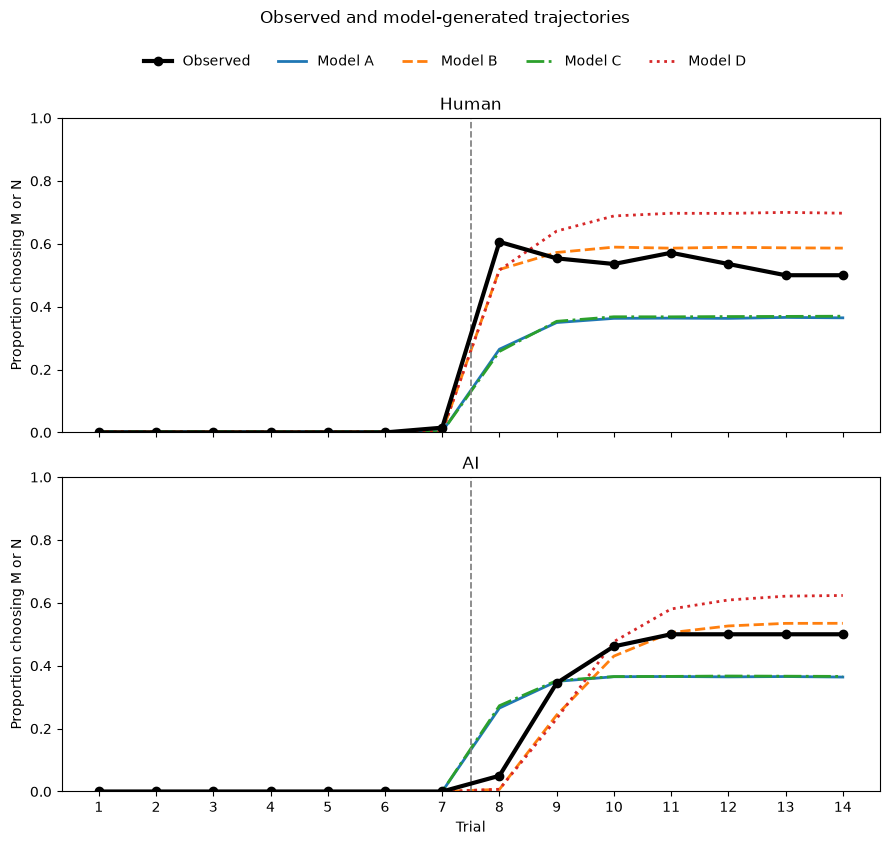

In [77]:
# ============================================================
# FULL TRAJECTORY PLOT
# ============================================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(9, 8),
    sharex=True,
    sharey=True,
)

model_styles = {
    "A": "-",
    "B": "--",
    "C": "-.",
    "D": ":",
}


for ax, type_name in zip(
    axes,
    ["Human", "AI"],
):

    # --------------------------------------------------------
    # OBSERVED
    # --------------------------------------------------------

    obs = (
        observed_14.loc[
            observed_14["type"]
            == type_name
        ]
        .sort_values("round")
    )

    ax.plot(
        obs["round"],
        obs["switch_rate"],
        color="black",
        linewidth=3,
        marker="o",
        label="Observed",
        zorder=10,
    )

    # --------------------------------------------------------
    # MODELS
    # --------------------------------------------------------

    for model in MODELS:

        sim = (
            full_model_simulations[
                model
            ]["summary"]
            .loc[
                lambda d:
                    d["type"] == type_name
            ]
            .sort_values("round")
        )

        ax.plot(
            sim["round"],
            sim["mean"],
            linewidth=2,
            linestyle=model_styles[model],
            label=f"Model {model}",
        )

    # --------------------------------------------------------
    # PAYOFF CHANGE
    # --------------------------------------------------------

    ax.axvline(
        7.5,
        color="grey",
        linestyle="--",
        linewidth=1.25,
    )

    ax.set_ylim(0, 1)

    ax.set_ylabel(
        "Proportion choosing M or N"
    )

    ax.set_title(type_name)


axes[-1].set_xlabel("Trial")

axes[-1].set_xticks(
    range(1, 15)
)

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, 1.01),
)

fig.suptitle(
    "Observed and model-generated trajectories",
    y=1.05,
)

fig.tight_layout()
plt.savefig("my_plot.png", dpi=300, bbox_inches="tight")
plt.show()

In [74]:
# ============================================================
# RMSE: observed vs simulated trajectories, trials 8-14
# ============================================================

rmse_rows = []

for model in MODELS:

    sim = full_model_simulations[model]["summary"]

    for type_name in ["Human", "AI"]:

        obs_type = (
            observed_14.loc[
                (observed_14["type"] == type_name)
                & (observed_14["round"] >= 8)
            ]
            [["round", "switch_rate"]]
            .rename(columns={"switch_rate": "observed"})
        )

        sim_type = (
            sim.loc[
                (sim["type"] == type_name)
                & (sim["round"] >= 8)
            ]
            [["round", "mean"]]
            .rename(columns={"mean": "predicted"})
        )

        merged = obs_type.merge(
            sim_type,
            on="round",
            how="inner"
        )

        rmse = np.sqrt(
            np.mean(
                (merged["observed"] - merged["predicted"]) ** 2
            )
        )

        rmse_rows.append({
            "model": model,
            "type": type_name,
            "RMSE": rmse
        })


rmse_by_type = pd.DataFrame(rmse_rows)

display(
    rmse_by_type.sort_values(
        ["type", "RMSE"]
    )
)

,model,type,RMSE
3,B,AI,0.048312
7,D,AI,0.095025
1,A,AI,0.135583
5,C,AI,0.136405
2,B,Human,0.064364
6,D,Human,0.150909
4,C,Human,0.204684
0,A,Human,0.206199


In [75]:
# ============================================================
# Overall RMSE across Human + AI trajectories
# ============================================================

overall_rows = []

for model in MODELS:

    sim = full_model_simulations[model]["summary"]

    obs_post = (
        observed_14.loc[
            observed_14["round"] >= 8,
            ["round", "type", "switch_rate"]
        ]
        .rename(columns={"switch_rate": "observed"})
    )

    sim_post = (
        sim.loc[
            sim["round"] >= 8,
            ["round", "type", "mean"]
        ]
        .rename(columns={"mean": "predicted"})
    )

    merged = obs_post.merge(
        sim_post,
        on=["round", "type"]
    )

    rmse = np.sqrt(
        np.mean(
            (merged["observed"] - merged["predicted"]) ** 2
        )
    )

    overall_rows.append({
        "model": model,
        "RMSE": rmse
    })


rmse_overall = (
    pd.DataFrame(overall_rows)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(rmse_overall)

,model,RMSE
0,B,0.056907
1,D,0.126102
2,C,0.173928
3,A,0.174501


In [76]:
# RMSE by model and actor type, trials 8-14

rmse_rows = []

for model in MODELS:
    sim = full_model_simulations[model]["summary"]

    for type_name in ["Human", "AI"]:

        obs = (
            observed_14.loc[
                (observed_14["type"] == type_name)
                & (observed_14["round"] >= 8),
                ["round", "switch_rate"]
            ]
            .rename(columns={"switch_rate": "observed"})
        )

        pred = (
            sim.loc[
                (sim["type"] == type_name)
                & (sim["round"] >= 8),
                ["round", "mean"]
            ]
            .rename(columns={"mean": "predicted"})
        )

        dat = obs.merge(pred, on="round")

        rmse = np.sqrt(
            np.mean((dat["observed"] - dat["predicted"]) ** 2)
        )

        rmse_rows.append({
            "model": model,
            "type": type_name,
            "RMSE": rmse
        })

rmse_by_type = (
    pd.DataFrame(rmse_rows)
    .sort_values(["type", "RMSE"])
    .reset_index(drop=True)
)

display(rmse_by_type)

,model,type,RMSE
0,B,AI,0.048312
1,D,AI,0.095025
2,A,AI,0.135583
3,C,AI,0.136405
4,B,Human,0.064364
5,D,Human,0.150909
6,C,Human,0.204684
7,A,Human,0.206199
